In [1]:
# Data manipulation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

# Machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("All machine learning libraries imported successfully!")

All machine learning libraries imported successfully!


In [2]:
from pathlib import Path

# Load the dataset exported from Notebook 1
data_path = Path("Outputs/NHANES_Hypertension_Model_Data.csv")

model_data = pd.read_csv(data_path)

print("Dataset shape:", model_data.shape)
print("\nTarget distribution:")
print(model_data["HYPERTENSION"].value_counts())

display(model_data.head())

Dataset shape: (5072, 8)

Target distribution:
HYPERTENSION
1    2986
0    2086
Name: count, dtype: int64


,SEQN,RIDAGEYR,RIAGENDR,BMXBMI,BMXWAIST,SMOKING_STATUS,ANY_PHYSICAL_ACTIVITY,HYPERTENSION
0,93705.0,66.0,2.0,31.7,101.8,Former,1.0,1
1,93708.0,66.0,2.0,23.7,88.2,Never,1.0,1
2,93709.0,75.0,2.0,38.9,113.0,Current,1.0,1
3,93711.0,56.0,1.0,21.3,86.6,Never,1.0,0
4,93713.0,67.0,1.0,23.5,99.7,Current,1.0,0


In [3]:
# Define the predictor columns
feature_cols = [
    "RIDAGEYR",
    "RIAGENDR",
    "BMXBMI",
    "BMXWAIST",
    "SMOKING_STATUS",
    "ANY_PHYSICAL_ACTIVITY"
]

# X contains the predictors
X = model_data[feature_cols].copy()

# y contains the binary hypertension outcome
y = model_data["HYPERTENSION"].astype(int)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (5072, 6)
Target shape: (5072,)


In [4]:
# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dimensions
print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4) * 100)

Training predictors: (4057, 6)
Testing predictors: (1015, 6)

Training target distribution:
HYPERTENSION
1    58.86
0    41.14
Name: proportion, dtype: float64

Testing target distribution:
HYPERTENSION
1    58.92
0    41.08
Name: proportion, dtype: float64


In [5]:
# Define numerical and categorical predictors
numeric_features = [
    "RIDAGEYR",
    "BMXBMI",
    "BMXWAIST"
]

categorical_features = [
    "RIAGENDR",
    "SMOKING_STATUS",
    "ANY_PHYSICAL_ACTIVITY"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing workflows
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [6]:
# Create a logistic regression pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic regression pipeline created successfully!")

Logistic regression pipeline created successfully!


In [7]:
# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Cross-validation strategy and metrics defined!")

Cross-validation strategy and metrics defined!


In [8]:
# Evaluate logistic regression using training data only
logistic_cv = cross_validate(
    estimator=logistic_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# Summarize validation performance
logistic_results = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean CV Score": [
        logistic_cv[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Standard Deviation": [
        logistic_cv[f"test_{metric}"].std()
        for metric in scoring
    ],
    "Mean Training Score": [
        logistic_cv[f"train_{metric}"].mean()
        for metric in scoring
    ]
})

display(logistic_results.round(4))

,Metric,Mean CV Score,Standard Deviation,Mean Training Score
0,accuracy,0.7501,0.0166,0.7522
1,precision,0.7674,0.0142,0.7686
2,recall,0.8258,0.0175,0.8284
3,f1,0.7955,0.0136,0.7974
4,roc_auc,0.7999,0.0096,0.8014


In [9]:
# Display validation metrics for each cross-validation fold
fold_results = pd.DataFrame({
    metric: logistic_cv[f"test_{metric}"]
    for metric in scoring
})

fold_results.index = [
    f"Fold {i}" for i in range(1, 6)
]

display(fold_results.round(4))

,accuracy,precision,recall,f1,roc_auc
Fold 1,0.7734,0.7784,0.8598,0.8171,0.8152
Fold 2,0.7414,0.7607,0.8180,0.7883,0.7934
Fold 3,0.7546,0.7741,0.8243,0.7984,0.8027
Fold 4,0.7238,0.7428,0.8113,0.7756,0.7866
Fold 5,0.7571,0.7811,0.8155,0.7979,0.8015


In [10]:
# Define five machine learning algorithms
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "Support Vector Machine": SVC(
        kernel="rbf",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Number of candidate models:", len(models))

Number of candidate models: 5


In [11]:
# Store cross-validation results
comparison_results = []

for name, classifier in models.items():

    # Create a fresh pipeline for each algorithm
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Evaluate using training data only
    cv_results = cross_validate(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Store mean and standard deviation of each metric
    result = {"Model": name}

    for metric in scoring:
        result[metric] = cv_results[
            f"test_{metric}"
        ].mean()

        result[f"{metric}_std"] = cv_results[
            f"test_{metric}"
        ].std()

    comparison_results.append(result)

# Convert results to a DataFrame
comparison_df = pd.DataFrame(comparison_results)

# Sort by mean ROC-AUC
comparison_df = comparison_df.sort_values(
    by="roc_auc",
    ascending=False
)

# Display main metrics
display(
    comparison_df[
        ["Model", "accuracy", "precision",
         "recall", "f1", "roc_auc"]
    ].round(4)
)

,Model,accuracy,precision,recall,f1,roc_auc
4,Gradient Boosting,0.7565,0.7683,0.8396,0.8023,0.8008
0,Logistic Regression,0.7501,0.7674,0.8258,0.7955,0.7999
3,Support Vector Machine,0.7481,0.7538,0.8497,0.7988,0.7897
2,Random Forest,0.7237,0.7462,0.8044,0.7741,0.7693
1,Decision Tree,0.6564,0.7064,0.7131,0.7096,0.6439


In [12]:
# Create an unrestricted decision tree pipeline
tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Evaluate training and validation performance
tree_cv = cross_validate(
    estimator=tree_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# Compare training and validation metrics
tree_results = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Training": [
        tree_cv[f"train_{metric}"].mean()
        for metric in scoring
    ],
    "Validation": [
        tree_cv[f"test_{metric}"].mean()
        for metric in scoring
    ]
})

tree_results["Gap"] = (
    tree_results["Training"] -
    tree_results["Validation"]
)

display(tree_results.round(4))

,Metric,Training,Validation,Gap
0,accuracy,0.9993,0.6564,0.3429
1,precision,0.9989,0.7064,0.2924
2,recall,0.9999,0.7131,0.2868
3,f1,0.9994,0.7096,0.2897
4,roc_auc,1.0000,0.6439,0.3560


In [13]:
from sklearn.model_selection import GridSearchCV

# Define candidate regularization strengths
logistic_param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

# Create logistic regression pipeline
logistic_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Parameter combinations:", len(logistic_param_grid["classifier__C"]))

Parameter combinations: 6


In [14]:
logistic_grid_search = GridSearchCV(
    estimator=logistic_tuning_pipeline,
    param_grid=logistic_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

logistic_grid_search.fit(X_train, y_train)

print("Best parameters:")
print(logistic_grid_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(logistic_grid_search.best_score_, 4))

Best parameters:
{'classifier__C': 0.01}

Best CV ROC-AUC:
0.8002


In [15]:
logistic_tuning_results = pd.DataFrame(
    logistic_grid_search.cv_results_
)

display(
    logistic_tuning_results[
        [
            "param_classifier__C",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").round(4)
)

,param_classifier__C,mean_test_score,std_test_score,rank_test_score
1,0.010,0.8002,0.0099,1
3,1.000,0.7999,0.0096,2
2,0.100,0.7999,0.0096,3
4,10.000,0.7998,0.0096,4
5,100.000,0.7998,0.0096,5
0,0.001,0.7983,0.0117,6


In [16]:
# Create gradient boosting pipeline
gb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

# Define candidate hyperparameter values
gb_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.03, 0.1, 0.2],
    "classifier__max_depth": [1, 2, 3]
}

n_combinations = (
    len(gb_param_grid["classifier__n_estimators"]) *
    len(gb_param_grid["classifier__learning_rate"]) *
    len(gb_param_grid["classifier__max_depth"])
)

print("Hyperparameter combinations:", n_combinations)
print("Total CV fits:", n_combinations * 5)

Hyperparameter combinations: 18
Total CV fits: 90


In [17]:
gb_grid_search = GridSearchCV(
    estimator=gb_tuning_pipeline,
    param_grid=gb_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

gb_grid_search.fit(X_train, y_train)

print("Best parameters:")
print(gb_grid_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(gb_grid_search.best_score_, 4))

Best parameters:
{'classifier__learning_rate': 0.03, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}

Best CV ROC-AUC:
0.8034


In [18]:
gb_tuning_results = pd.DataFrame(
    gb_grid_search.cv_results_
)

display(
    gb_tuning_results[
        [
            "param_classifier__n_estimators",
            "param_classifier__learning_rate",
            "param_classifier__max_depth",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
    .round(4)
)

,param_classifier__n_estimators,param_classifier__learning_rate,param_classifier__max_depth,mean_test_score,std_test_score,rank_test_score
4,100,0.03,3,0.8034,0.0102,1
5,200,0.03,3,0.8031,0.0123,2
8,100,0.10,2,0.8023,0.0115,3
3,200,0.03,2,0.8023,0.0104,4
10,100,0.10,3,0.8008,0.0134,5
9,200,0.10,2,0.8006,0.0125,6
2,100,0.03,2,0.8003,0.0090,7
14,100,0.20,2,0.7991,0.0136,8
11,200,0.10,3,0.7968,0.0128,9
7,200,0.10,1,0.7966,0.0100,10


In [19]:
tuning_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Gradient Boosting"
    ],
    "Baseline CV ROC-AUC": [
        0.7999,
        0.8008
    ],
    "Best Tuned CV ROC-AUC": [
        logistic_grid_search.best_score_,
        gb_grid_search.best_score_
    ]
})

tuning_comparison["Improvement"] = (
    tuning_comparison["Best Tuned CV ROC-AUC"] -
    tuning_comparison["Baseline CV ROC-AUC"]
)

display(tuning_comparison.round(4))

,Model,Baseline CV ROC-AUC,Best Tuned CV ROC-AUC,Improvement
0,Logistic Regression,0.7999,0.8002,0.0003
1,Gradient Boosting,0.8008,0.8034,0.0026


In [20]:
# Define hyperparameter grid
tree_param_grid = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10, 20]
}

# Tune decision tree using training data only
tree_grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

tree_grid_search.fit(X_train, y_train)

print("Best parameters:")
print(tree_grid_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(tree_grid_search.best_score_, 4))

Best parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 2}

Best CV ROC-AUC:
0.7833


In [21]:
# Best decision tree selected by grid search
best_tree = tree_grid_search.best_estimator_

# Calculate ROC-AUC on the training data
train_probabilities = best_tree.predict_proba(X_train)[:, 1]

train_auc = roc_auc_score(
    y_train,
    train_probabilities
)

# Compare before and after tuning
tree_comparison = pd.DataFrame({
    "Model": [
        "Unrestricted Decision Tree",
        "Tuned Decision Tree"
    ],
    "Training ROC-AUC": [
        1.0000,
        train_auc
    ],
    "CV ROC-AUC": [
        0.6439,
        tree_grid_search.best_score_
    ]
})

tree_comparison["Train-CV Gap"] = (
    tree_comparison["Training ROC-AUC"] -
    tree_comparison["CV ROC-AUC"]
)

display(tree_comparison.round(4))

,Model,Training ROC-AUC,CV ROC-AUC,Train-CV Gap
0,Unrestricted Decision Tree,1.0000,0.6439,0.3561
1,Tuned Decision Tree,0.8182,0.7833,0.0349


In [22]:
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate
)

# Three outer folds for model evaluation
outer_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=123
)

# Reuse our original five-fold CV for tuning
inner_cv = cv

# Define model searches
tuned_models = {
    "Logistic Regression": (
        logistic_tuning_pipeline,
        logistic_param_grid
    ),
    "Gradient Boosting": (
        gb_tuning_pipeline,
        gb_param_grid
    ),
    "Decision Tree": (
        tree_pipeline,
        tree_param_grid
    )
}

In [24]:
nested_results = []

for name, (pipeline, param_grid) in tuned_models.items():


    # Hyperparameter tuning occurs inside each outer training fold
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=1,
        refit=True
    )

    # Evaluate tuned model on outer validation folds
    scores = cross_validate(
        estimator=search,
        X=X_train,
        y=y_train,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": name}

    for metric in scoring:
        result[metric] = scores[
            f"test_{metric}"
        ].mean()

        result[f"{metric}_std"] = scores[
            f"test_{metric}"
        ].std()

    nested_results.append(result)

nested_comparison = pd.DataFrame(nested_results)

display(
    nested_comparison[
        ["Model", "accuracy", "precision",
         "recall", "f1", "roc_auc", "roc_auc_std"]
    ].sort_values(
        "roc_auc", ascending=False
    ).round(4)
)

,Model,accuracy,precision,recall,f1,roc_auc,roc_auc_std
1,Gradient Boosting,0.7535,0.7632,0.8430,0.8009,0.8024,0.0165
0,Logistic Regression,0.7555,0.7659,0.8417,0.8019,0.7992,0.0174
2,Decision Tree,0.7446,0.7660,0.8153,0.7898,0.7806,0.0187


In [25]:
# Retrieve the optimized pipelines
final_logistic = logistic_grid_search.best_estimator_
final_gb = gb_grid_search.best_estimator_

# Explicitly refit both models on all training participants
final_logistic.fit(X_train, y_train)
final_gb.fit(X_train, y_train)

print("Both final models fitted successfully!")

Both final models fitted successfully!


In [26]:
# Define final models
final_models = {
    "Logistic Regression": final_logistic,
    "Gradient Boosting": final_gb
}

test_results = []

for name, model in final_models.items():

    # Generate binary predictions
    y_pred = model.predict(X_test)

    # Generate predicted probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate performance metrics
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.7635,0.7609,0.8729,0.8131,0.8248
1,Gradient Boosting,0.7704,0.7696,0.8712,0.8173,0.8225


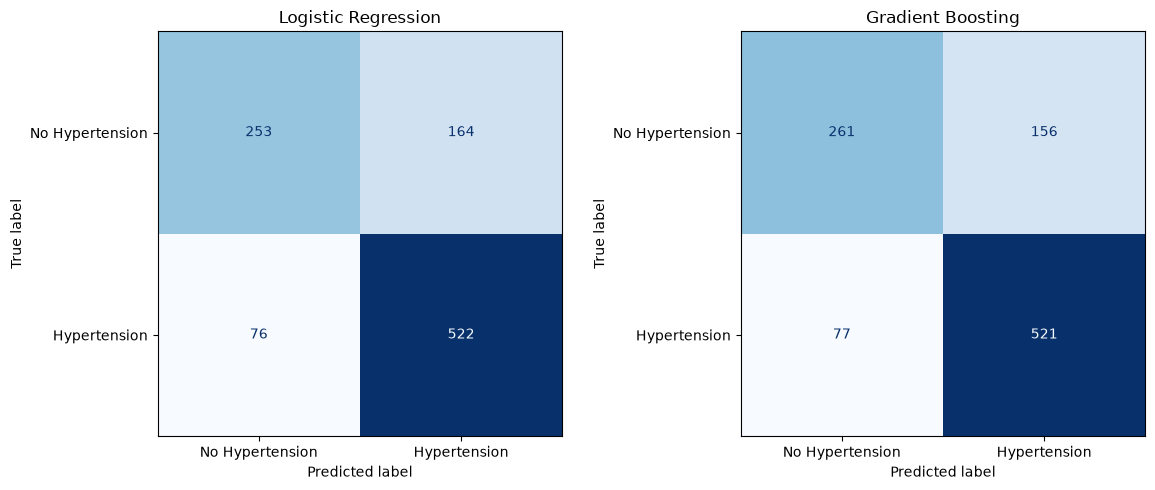

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, final_models.items()):

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No Hypertension", "Hypertension"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

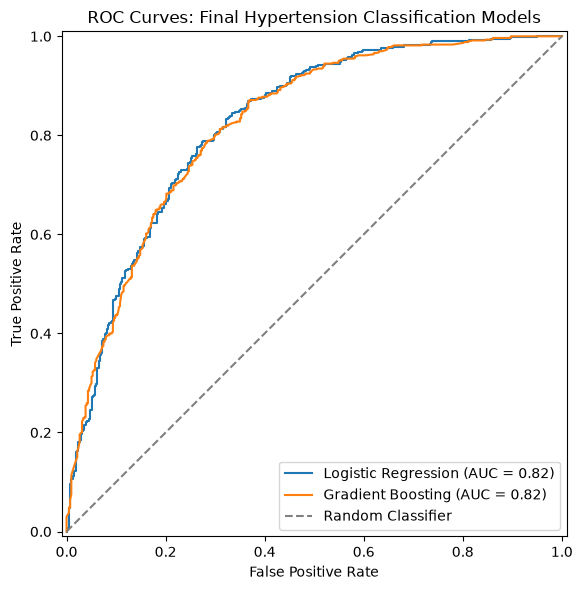

In [28]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in final_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

# Diagonal reference line for random discrimination
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

ax.set_title("ROC Curves: Final Hypertension Classification Models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [29]:
# Extract the fitted preprocessing pipeline and classifier
fitted_preprocessor = final_logistic.named_steps["preprocessor"]
logistic_model = final_logistic.named_steps["classifier"]

# Retrieve transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract logistic regression coefficients
coefficients = logistic_model.coef_[0]

# Create coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(coefficients)
})

# Sort by coefficient magnitude
coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(coef_df.round(4))

,Feature,Coefficient,Odds Ratio,Absolute Coefficient
0,num__RIDAGEYR,0.9692,2.6358,0.9692
2,num__BMXWAIST,0.2912,1.3380,0.2912
1,num__BMXBMI,0.1757,1.1920,0.1757
4,cat__RIAGENDR_2.0,-0.1285,0.8794,0.1285
3,cat__RIAGENDR_1.0,0.1277,1.1362,0.1277
9,cat__ANY_PHYSICAL_ACTIVITY_1.0,-0.0556,0.9459,0.0556
8,cat__ANY_PHYSICAL_ACTIVITY_0.0,0.0548,1.0564,0.0548
6,cat__SMOKING_STATUS_Former,-0.0075,0.9925,0.0075
5,cat__SMOKING_STATUS_Current,0.0071,1.0071,0.0071
7,cat__SMOKING_STATUS_Never,-0.0003,0.9997,0.0003


In [30]:
from sklearn.base import clone
from sklearn.inspection import permutation_importance

# Models selected during tuning
interpretation_models = {
    "Logistic Regression": final_logistic,
    "Gradient Boosting": final_gb
}

importance_results = []

for name, model in interpretation_models.items():

    print(f"Calculating importance for {name}...")

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train), start=1
    ):

        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Refit a fresh model using only this fold's training data
        fold_model = clone(model)
        fold_model.fit(X_fold_train, y_fold_train)

        # Shuffle each original predictor and measure ROC-AUC loss
        result = permutation_importance(
            fold_model,
            X_fold_val,
            y_fold_val,
            scoring="roc_auc",
            n_repeats=10,
            random_state=42,
            n_jobs=-1
        )

        for feature, importance in zip(
            X_train.columns,
            result.importances_mean
        ):
            importance_results.append({
                "Model": name,
                "Fold": fold,
                "Feature": feature,
                "Importance": importance
            })

importance_df = pd.DataFrame(importance_results)

importance_summary = (
    importance_df
    .groupby(["Model", "Feature"])["Importance"]
    .agg(["mean", "std"])
    .reset_index()
)

display(
    importance_summary
    .sort_values(["Model", "mean"], ascending=[True, False])
    .round(4)
)

Calculating importance for Logistic Regression...
Calculating importance for Gradient Boosting...


,Model,Feature,mean,std
4,Gradient Boosting,RIDAGEYR,0.2452,0.0120
2,Gradient Boosting,BMXWAIST,0.0223,0.0091
1,Gradient Boosting,BMXBMI,0.0120,0.0032
3,Gradient Boosting,RIAGENDR,0.0077,0.0011
0,Gradient Boosting,ANY_PHYSICAL_ACTIVITY,0.0005,0.0007
5,Gradient Boosting,SMOKING_STATUS,0.0001,0.0001
10,Logistic Regression,RIDAGEYR,0.2349,0.0149
8,Logistic Regression,BMXWAIST,0.0177,0.0063
7,Logistic Regression,BMXBMI,0.0052,0.0041
9,Logistic Regression,RIAGENDR,0.0032,0.0024


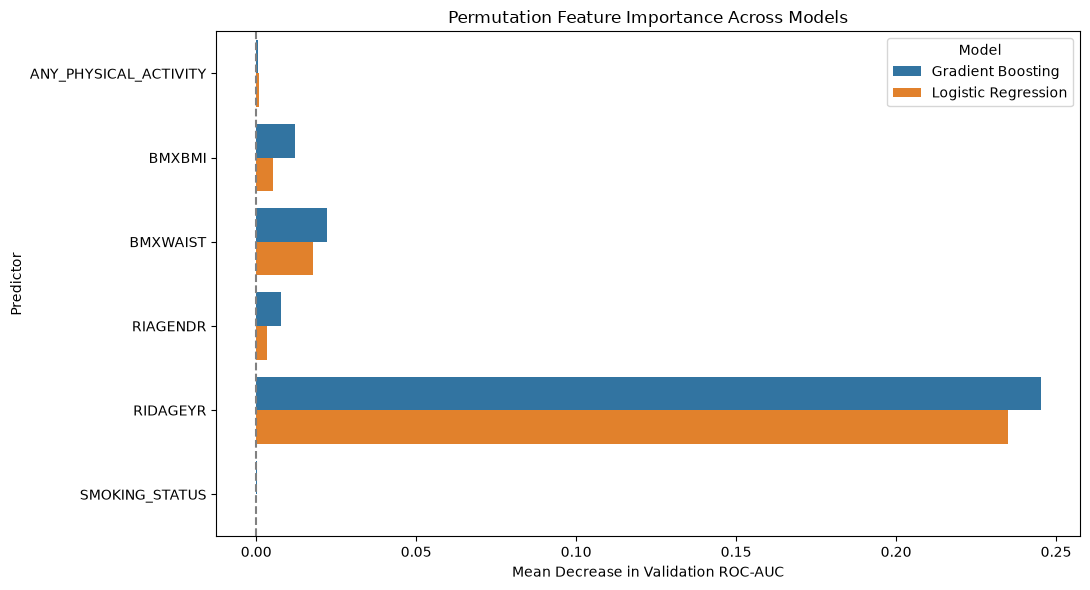

In [31]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=importance_summary,
    x="mean",
    y="Feature",
    hue="Model"
)

plt.axvline(0, color="gray", linestyle="--")

plt.title("Permutation Feature Importance Across Models")
plt.xlabel("Mean Decrease in Validation ROC-AUC")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

In [32]:
from sklearn.base import clone

# Preprocessing for the age-only model
age_preprocessor = ColumnTransformer(
    transformers=[
        (
            "age",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["RIDAGEYR"]
        )
    ]
)

# Age-only logistic regression
age_only_pipeline = Pipeline(steps=[
    ("preprocessor", age_preprocessor),
    ("classifier", LogisticRegression(
        C=logistic_grid_search.best_params_["classifier__C"],
        max_iter=2000,
        random_state=42
    ))
])

# Compare with the selected full logistic regression pipeline
baseline_models = {
    "Age Only": age_only_pipeline,
    "All Six Predictors": clone(final_logistic)
}

baseline_results = []

for name, model in baseline_models.items():

    features = (
        ["RIDAGEYR"]
        if name == "Age Only"
        else feature_cols
    )

    scores = cross_validate(
        estimator=model,
        X=X_train[features],
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    baseline_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

age_comparison = pd.DataFrame(baseline_results)

display(age_comparison.round(4))

,Model,Accuracy,Recall,F1,ROC-AUC
0,Age Only,0.7259,0.8136,0.7774,0.7787
1,All Six Predictors,0.7513,0.8392,0.7989,0.8002
